In [1]:
# Cell 1: Reload NaN-Safe COMPhysics, Clean Simlog Tensors & Cache Baseline Interpolators
import importlib
import scipy.io as sio
import numpy as np
import torch
import torch.nn as nn
from scipy.interpolate import LinearNDInterpolator, NearestNDInterpolator
import matplotlib.pyplot as plt
from tqdm.auto import tqdm
import com_physics
importlib.reload(com_physics)
from com_physics import COMPhysics

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

raw_data = sio.loadmat("../Data/python_training_data.mat", squeeze_me=True, struct_as_record=False)

# Set True to use the 23°C-setpoint Simscape Reference from Figure 2 / Table 1 of the paper,
# or False to use your 21°C-setpoint simlog_rule_Tx.mat runs.
USE_FIG2_23C_REF = True

def clean_array(arr):
    """Replaces any boundary NaNs/Infs from simlog interpolation via nearest valid value."""
    a = np.asarray(arr, dtype=np.float64).copy()
    if np.all(np.isfinite(a)):
        return a
    if a.ndim == 1:
        mask = np.isfinite(a)
        if np.any(mask):
            a[~mask] = np.interp(np.flatnonzero(~mask), np.flatnonzero(mask), a[mask])
        else:
            a[:] = 0.0
    else:
        for col in range(a.shape[1]):
            a[:, col] = clean_array(a[:, col])
    return a

# 1. Pre-build the 11 2D interpolators from tunedVariables_minus5_minus10.mat ONCE
TV = raw_data["baseline_TV"]
tv_amb = clean_array(TV.ambient)
tv_states = clean_array(TV.states)
tv_params = clean_array(TV.parameters)
IDX_STATE_0 = [7, 8, 4, 1, 0, 2, 4, 8, 5, 6, 5]

CACHED_INTERPS = []
for i in range(11):
    sj = IDX_STATE_0[i]
    pts = np.column_stack([tv_amb, tv_states[:, sj]])
    vals = tv_params[:, i]
    pts_round = np.round(pts, decimals=5)
    _, inv_idx = np.unique(pts_round, axis=0, return_inverse=True)
    u_pts = np.zeros((inv_idx.max() + 1, 2), dtype=np.float64)
    u_vals = np.zeros(inv_idx.max() + 1, dtype=np.float64)
    counts = np.bincount(inv_idx)
    np.add.at(u_pts[:, 0], inv_idx, pts[:, 0])
    np.add.at(u_pts[:, 1], inv_idx, pts[:, 1])
    np.add.at(u_vals, inv_idx, vals)
    u_pts /= counts[:, None]
    u_vals /= counts
    CACHED_INTERPS.append((sj, LinearNDInterpolator(u_pts, u_vals), NearestNDInterpolator(u_pts, u_vals)))

def evaluate_baseline_prepParaVec(tamb_c, X_np):
    X_2d = clean_array(np.atleast_2d(X_np))
    N = X_2d.shape[0]
    P_out = np.empty((N, 11), dtype=np.float32)
    amb_col = np.full(N, tamb_c, dtype=np.float64)
    for i, (sj, lin_fn, near_fn) in enumerate(CACHED_INTERPS):
        query = np.column_stack([amb_col, X_2d[:, sj]])
        p_i = lin_fn(query)
        nan_mask = ~np.isfinite(p_i)
        if np.any(nan_mask):
            p_i[nan_mask] = near_fn(query[nan_mask])
        P_out[:, i] = p_i
    return torch.from_numpy(P_out).to(device)

def build_torch_scenario(mat_struct, tamb_c):
    has_fig2 = hasattr(mat_struct, "X_fig2")
    use_f2 = USE_FIG2_23C_REF and has_fig2
    X = clean_array(mat_struct.X_fig2 if use_f2 else mat_struct.X)
    U = clean_array(mat_struct.U_fig2 if use_f2 else mat_struct.U)
    
    # Ensure physical units (Kelvin, Pa, Watts) and non-negative actuator speeds/flows
    for tidx in [0, 1, 2, 4, 7, 8]:
        if np.mean(X[:, tidx]) < 150.0:
            X[:, tidx] += 273.15
    for pidx in [5, 6]:
        if np.mean(X[:, pidx]) < 1e3:
            X[:, pidx] *= 1e6
    U[:, :6] = np.maximum(U[:, :6], 0.0)
    if np.max(U[:, 4]) <= 10.0:
        U[:, 4] *= 4000.0  # Convert [0,1] heater command to [0, 4000] Watts

    est = {}
    for f in mat_struct.est._fieldnames:
        arr = clean_array(getattr(mat_struct.est, f))
        if f == "envT" and np.mean(arr) < 150.0:
            arr += 273.15
        est[f] = torch.tensor(arr, dtype=torch.float32, device=device)

    ctrl = {f: torch.tensor(clean_array(getattr(mat_struct.ctrl, f)),
                            dtype=torch.float32, device=device)
            for f in mat_struct.ctrl._fieldnames}

    X_t = torch.tensor(X, dtype=torch.float32, device=device)
    U_t = torch.tensor(U, dtype=torch.float32, device=device)

    N_steps = X.shape[0]
    tamb_col = torch.full((N_steps, 1), float(tamb_c), dtype=torch.float32, device=device)
    batI_col = est["batImeas"].unsqueeze(1)
    comp_col = U_t[:, 0:1]
    heat_col = U_t[:, 4:5]
    Z_t = torch.cat([tamb_col, X_t, batI_col, comp_col, heat_col], dim=1)

    P_base = evaluate_baseline_prepParaVec(tamb_c, X)
    assert torch.isfinite(X_t).all() and torch.isfinite(U_t).all() and torch.isfinite(P_base).all(), "NaN found!"
    return {"Tamb_C": tamb_c, "X": X_t, "U": U_t, "Z": Z_t, "est": est, "ctrl": ctrl, "P_baseline": P_base}

data_by_temp = {
    -5:  build_torch_scenario(raw_data["T5"], -5.0),
    -7:  build_torch_scenario(raw_data["T7"], -7.0),
    -10: build_torch_scenario(raw_data["T10"], -10.0),
}
print("✓ All scenarios verified finite (0 NaNs) and fast interpolators cached!")

Using device: cpu
✓ All scenarios verified finite (0 NaNs) and fast interpolators cached!


In [2]:
# Cell 2: Physics Sanity Check (1-Step RK4 Forward Pass)
com = COMPhysics().to(device)

# Scale weights G so temperature errors (~1 K), SOC (~0.01), and pressure (~1e5 Pa) are balanced
state_scales = torch.tensor([1.0, 1.0, 1.0, 0.01, 1.0, 1e5, 1e5, 1.0, 1.0], device=device)
G_weights = 1.0 / (state_scales ** 2)

for tamb, sc in data_by_temp.items():
    X, U, est, ctrl = sc["X"], sc["U"], sc["est"], sc["ctrl"]
    est_k = {k: v[:-1] for k, v in est.items()}
    ctrl_k = {k: v[:-1] for k, v in ctrl.items()}
    
    # 1) Nominal P = 1
    P_ones = torch.ones((X.shape[0] - 1, 11), device=device)
    X_next_nom = com.step_rk4(X[:-1], U[:-1], est_k, ctrl_k, P_ones, dt=1.0)
    
    # 2) Prashant's Baseline Interpolated P
    P_base = sc["P_baseline"][:-1]
    X_next_base = com.step_rk4(X[:-1], U[:-1], est_k, ctrl_k, P_base, dt=1.0)
    
    err_nom = torch.mean(torch.abs(X_next_nom - X[1:]), dim=0).cpu().numpy()
    err_base = torch.mean(torch.abs(X_next_base - X[1:]), dim=0).cpu().numpy()
    print(f"Tamb = {tamb}°C | 1-Step MAE CabAirT -> Nominal P=1: {err_nom[8]:.4f} K | Baseline Table: {err_base[8]:.4f} K")
    print(f"Tamb = {tamb}°C | 1-Step MAE BatT    -> Nominal P=1: {err_nom[4]:.4f} K | Baseline Table: {err_base[4]:.4f} K\n")

Tamb = -5°C | 1-Step MAE CabAirT -> Nominal P=1: 0.0124 K | Baseline Table: 0.0240 K
Tamb = -5°C | 1-Step MAE BatT    -> Nominal P=1: 0.0021 K | Baseline Table: 0.0036 K

Tamb = -7°C | 1-Step MAE CabAirT -> Nominal P=1: 0.0132 K | Baseline Table: 0.0271 K
Tamb = -7°C | 1-Step MAE BatT    -> Nominal P=1: 0.0024 K | Baseline Table: 0.0032 K

Tamb = -10°C | 1-Step MAE CabAirT -> Nominal P=1: 0.0144 K | Baseline Table: 0.0413 K
Tamb = -10°C | 1-Step MAE BatT    -> Nominal P=1: 0.0029 K | Baseline Table: 0.0031 K



In [3]:
# Cell 3: Define Neural Network & Train with 1-Step Teacher Forcing
# Following Section V of the paper: Train on -5°C and -10°C, and hold out -7°C as an unseen test temperature!
train_temps = [-5, -10]
val_temps   = [-7]

def stack_transitions(temp_list):
    Z_list, Xk_list, Xnext_list, U_list, Pbase_list = [], [], [], [], []
    est_lists = {k: [] for k in data_by_temp[-5]["est"].keys()}
    ctrl_lists = {k: [] for k in data_by_temp[-5]["ctrl"].keys()}
    
    for t in temp_list:
        sc = data_by_temp[t]
        Z_list.append(sc["Z"][:-1])
        Xk_list.append(sc["X"][:-1])
        Xnext_list.append(sc["X"][1:])
        U_list.append(sc["U"][:-1])
        Pbase_list.append(sc["P_baseline"][:-1])
        for k, v in sc["est"].items():
            est_lists[k].append(v[:-1])
        for k, v in sc["ctrl"].items():
            ctrl_lists[k].append(v[:-1])
            
    return (
        torch.cat(Z_list, dim=0),
        torch.cat(Xk_list, dim=0),
        torch.cat(Xnext_list, dim=0),
        torch.cat(U_list, dim=0),
        torch.cat(Pbase_list, dim=0),
        {k: torch.cat(v, dim=0) for k, v in est_lists.items()},
        {k: torch.cat(v, dim=0) for k, v in ctrl_lists.items()},
    )

Z_tr, Xk_tr, Xnext_tr, U_tr, Pbase_tr, est_tr, ctrl_tr = stack_transitions(train_temps)

# Compute feature normalization statistics on training set
z_mean = Z_tr.mean(dim=0, keepdim=True)
z_std  = Z_tr.std(dim=0, keepdim=True) + 1e-6

# Determine parameter bounds from baseline TV table with safety margin
p_min = torch.tensor( np.minimum(0.0, tv_params.min(axis=0) - 0.5), dtype=torch.float32, device=device )
p_max = torch.tensor( np.maximum(2.0, tv_params.max(axis=0) + 1.0), dtype=torch.float32, device=device )

class ParameterEstimatorNN(nn.Module):
    def __init__(self, in_dim=13, hidden_dim=64, p_min=p_min, p_max=p_max):
        super().__init__()
        self.register_buffer("p_min", p_min)
        self.register_buffer("p_max", p_max)
        self.net = nn.Sequential(
            nn.Linear(in_dim, hidden_dim),
            nn.SiLU(),
            nn.Linear(hidden_dim, hidden_dim),
            nn.SiLU(),
            nn.Linear(hidden_dim, 11)
        )

    def forward(self, z_norm):
        return self.p_min + (self.p_max - self.p_min) * torch.sigmoid(self.net(z_norm))

nn_model = ParameterEstimatorNN(in_dim=Z_tr.shape[1], hidden_dim=64).to(device)
optimizer = torch.optim.AdamW(nn_model.parameters(), lr=3e-3, weight_decay=1e-4)

# Step A: Quick 100-epoch warm-start pre-training on baseline P (as planned in Section 5.2 of your report!)
Z_tr_norm = (Z_tr - z_mean) / z_std
for ep in range(100):
    optimizer.zero_grad()
    loss_pre = torch.mean((nn_model(Z_tr_norm) - Pbase_tr) ** 2)
    loss_pre.backward()
    optimizer.step()
print(f"Warm-start pre-training MSE vs lookup table: {loss_pre.item():.5f}")

# Step B: End-to-End Teacher-Forced Physics Training on 1-Step RK4 State Error
batch_size = 512
N_samples = Xk_tr.shape[0]
indices = torch.arange(N_samples, device=device)

for epoch in range(1, 151):
    nn_model.train()
    perm = indices[torch.randperm(N_samples)]
    epoch_loss = 0.0
    
    for start in range(0, N_samples, batch_size):
        b_idx = perm[start : start + batch_size]
        optimizer.zero_grad()
        
        P_pred = nn_model(Z_tr_norm[b_idx])
        est_b  = {k: v[b_idx] for k, v in est_tr.items()}
        ctrl_b = {k: v[b_idx] for k, v in ctrl_tr.items()}
        
        # 1-Step Teacher-Forced RK4 propagation from ground-truth Xk_tr[b_idx]
        X_next_pred = com.step_rk4(Xk_tr[b_idx], U_tr[b_idx], est_b, ctrl_b, P_pred, dt=1.0)
        
        err = X_next_pred - Xnext_tr[b_idx]
        state_loss = torch.mean(torch.sum(G_weights * (err ** 2), dim=-1))
        reg_loss   = 1e-4 * torch.mean((P_pred - Pbase_tr[b_idx]) ** 2)
        
        loss = state_loss + reg_loss
        loss.backward()
        optimizer.step()
        epoch_loss += state_loss.item() * len(b_idx)
        
    if epoch % 25 == 0:
        # Evaluate on unseen -7°C validation run
        nn_model.eval()
        with torch.no_grad():
            sc7 = data_by_temp[-7]
            z7_norm = (sc7["Z"][:-1] - z_mean) / z_std
            P7_nn = nn_model(z7_norm)
            est7 = {k: v[:-1] for k, v in sc7["est"].items()}
            ctrl7 = {k: v[:-1] for k, v in sc7["ctrl"].items()}
            X7_pred = com.step_rk4(sc7["X"][:-1], sc7["U"][:-1], est7, ctrl7, P7_nn, dt=1.0)
            val_loss = torch.mean(torch.sum(G_weights * ((X7_pred - sc7["X"][1:]) ** 2), dim=-1)).item()
        print(f"Epoch {epoch:03d} | Train 1-Step Loss (-5,-10°C): {epoch_loss/N_samples:.6f} | Val 1-Step Loss (-7°C): {val_loss:.6f}")

Warm-start pre-training MSE vs lookup table: 1.38396
Epoch 025 | Train 1-Step Loss (-5,-10°C): 0.007131 | Val 1-Step Loss (-7°C): 0.005187
Epoch 050 | Train 1-Step Loss (-5,-10°C): 0.004937 | Val 1-Step Loss (-7°C): 0.004698
Epoch 075 | Train 1-Step Loss (-5,-10°C): 0.004333 | Val 1-Step Loss (-7°C): 0.004384
Epoch 100 | Train 1-Step Loss (-5,-10°C): 0.004260 | Val 1-Step Loss (-7°C): 0.004321
Epoch 125 | Train 1-Step Loss (-5,-10°C): 0.004259 | Val 1-Step Loss (-7°C): 0.004329
Epoch 150 | Train 1-Step Loss (-5,-10°C): 0.004214 | Val 1-Step Loss (-7°C): 0.004326


In [4]:
# Cell 4: Evaluate 1-Step Error & 30-Step MPC Horizon Rollout Error (Eq. 2 of Planning Report)
nn_model.eval()
horizon = 30
STATE_NAMES = [
    "T_mot (K)", "T_inv (K)", "T_dcdc (K)", "SOC (-)", "T_b (K)",
    "p_in (Pa)", "p_out (Pa)", "T_int (K)", "T_cair (K)"
]

print("================================================================================")
print("30-Step MPC Horizon MAE Comparison: Baseline Interpolation vs. Neural Network")
print("================================================================================")

for tamb in [-5, -7, -10]:
    sc = data_by_temp[tamb]
    X, U, est, ctrl = sc["X"], sc["U"], sc["est"], sc["ctrl"]
    T_len = X.shape[0] - horizon
    
    with torch.no_grad():
        z_norm = (sc["Z"][:T_len] - z_mean) / z_std
        P_nn   = nn_model(z_norm)
        P_base = sc["P_baseline"][:T_len]
        
        x_roll_nn   = X[:T_len].clone()
        x_roll_base = X[:T_len].clone()
        
        err_nn   = torch.zeros_like(x_roll_nn)
        err_base = torch.zeros_like(x_roll_base)
        
        # Unroll 30 seconds holding P_k fixed over the horizon (matching NMPC Step 5-6)
        for i in range(horizon):
            u_i    = U[i : i + T_len]
            est_i  = {k: v[i : i + T_len] for k, v in est.items()}
            ctrl_i = {k: v[i : i + T_len] for k, v in ctrl.items()}
            
            x_roll_nn   = com.step_rk4(x_roll_nn,   u_i, est_i, ctrl_i, P_nn,   dt=1.0)
            x_roll_base = com.step_rk4(x_roll_base, u_i, est_i, ctrl_i, P_base, dt=1.0)
            
            x_true = X[i + 1 : i + 1 + T_len]
            err_nn   += torch.abs(x_roll_nn   - x_true) / horizon
            err_base += torch.abs(x_roll_base - x_true) / horizon
            
        mae_nn   = torch.mean(err_nn,   dim=0).cpu().numpy()
        mae_base = torch.mean(err_base, dim=0).cpu().numpy()
        
    tag = "(UNSEEN TEST)" if tamb == -7 else "(TRAIN)"
    print(f"\nScenario Tamb = {tamb}°C {tag}:")
    for idx in [0, 1, 2, 4, 8]: # Key thermal states: motT, invT, dcdcT, batT, cabAirT
        print(f"  {STATE_NAMES[idx]:12s} | Baseline MAE: {mae_base[idx]:.4f} K | NN MAE: {mae_nn[idx]:.4f} K")

30-Step MPC Horizon MAE Comparison: Baseline Interpolation vs. Neural Network

Scenario Tamb = -5°C (TRAIN):
  T_mot (K)    | Baseline MAE: 0.1360 K | NN MAE: 0.1082 K
  T_inv (K)    | Baseline MAE: 0.1705 K | NN MAE: 0.1050 K
  T_dcdc (K)   | Baseline MAE: 0.2701 K | NN MAE: 0.2655 K
  T_b (K)      | Baseline MAE: 0.0536 K | NN MAE: 0.0281 K
  T_cair (K)   | Baseline MAE: 0.2436 K | NN MAE: 0.0338 K

Scenario Tamb = -7°C (UNSEEN TEST):
  T_mot (K)    | Baseline MAE: 0.1189 K | NN MAE: 0.1211 K
  T_inv (K)    | Baseline MAE: 0.1713 K | NN MAE: 0.1411 K
  T_dcdc (K)   | Baseline MAE: 0.2692 K | NN MAE: 0.2689 K
  T_b (K)      | Baseline MAE: 0.0451 K | NN MAE: 0.0272 K
  T_cair (K)   | Baseline MAE: 0.2900 K | NN MAE: 0.1501 K

Scenario Tamb = -10°C (TRAIN):
  T_mot (K)    | Baseline MAE: 0.0954 K | NN MAE: 0.1359 K
  T_inv (K)    | Baseline MAE: 0.1560 K | NN MAE: 0.1276 K
  T_dcdc (K)   | Baseline MAE: 0.2801 K | NN MAE: 0.3014 K
  T_b (K)      | Baseline MAE: 0.0435 K | NN MAE: 0.026

In [5]:
# Cell 5: Pre-cache Baseline Interpolators & Recreate Table 1 (Full 3600s Validation)
import numpy as np
import torch
from scipy.interpolate import LinearNDInterpolator, NearestNDInterpolator

# 1. Pre-build and cache the 11 baseline interpolators ONCE (matches persistent Fp in prepParaVec.m)
tv_amb_c = tv_amb - 273.15 if np.mean(tv_amb) > 100.0 else tv_amb.copy()

CACHED_INTERPS = []
for i in range(11):
    sj = IDX_STATE_0[i]
    pts = np.column_stack([tv_amb_c, tv_states[:, sj]])
    vals = tv_params[:, i]
    
    # Average duplicate (Tamb, state) points exactly as MATLAB's scatteredInterpolant does
    pts_rounded = np.round(pts, decimals=6)
    _, inv_idx = np.unique(pts_rounded, axis=0, return_inverse=True)
    u_pts = np.zeros((inv_idx.max() + 1, 2), dtype=np.float64)
    u_vals = np.zeros(inv_idx.max() + 1, dtype=np.float64)
    counts = np.bincount(inv_idx)
    np.add.at(u_pts[:, 0], inv_idx, pts[:, 0])
    np.add.at(u_pts[:, 1], inv_idx, pts[:, 1])
    np.add.at(u_vals, inv_idx, vals)
    u_pts /= counts[:, None]
    u_vals /= counts
    
    lin_fn = LinearNDInterpolator(u_pts, u_vals)
    near_fn = NearestNDInterpolator(u_pts, u_vals)
    CACHED_INTERPS.append((sj, lin_fn, near_fn))

def fast_prepParaVec(tamb_c, x_1d_np):
    """Evaluates the pre-built interpolators at a single state vector in microseconds."""
    P_out = np.empty((1, 11), dtype=np.float32)
    for i, (sj, lin_fn, near_fn) in enumerate(CACHED_INTERPS):
        pt = np.array([[tamb_c, x_1d_np[sj]]], dtype=np.float64)
        val = lin_fn(pt)[0]
        if not np.isfinite(val):
            val = near_fn(pt)[0]
        P_out[0, i] = val
    return torch.from_numpy(P_out).to(device)


# 2. Full 3600-second open-loop validation (Section V of Lokur & Murgovski, 2026)
z_min_clamp = Z_tr.min(dim=0, keepdim=True).values
z_max_clamp = Z_tr.max(dim=0, keepdim=True).values

def simulate_full_3600s(tamb, mode="nn"):
    nn_model.eval()
    sc = data_by_temp[tamb]
    X_ref, U, est, ctrl = sc["X"], sc["U"], sc["est"], sc["ctrl"]
    T_total = X_ref.shape[0]
    
    x_traj = torch.zeros_like(X_ref)
    x_curr = X_ref[0:1].clone()  # Initialized ONLY at t = 0s
    x_traj[0] = x_curr[0]
    tamb_col = torch.full((1, 1), float(tamb), dtype=torch.float32, device=device)
    
    with torch.no_grad():
        for k in range(T_total - 1):
            if mode == "baseline":
                P_k = fast_prepParaVec(tamb, x_curr[0].cpu().numpy())
            else:
                z_k = torch.cat([
                    tamb_col, x_curr,
                    est["batImeas"][k:k+1].unsqueeze(1),
                    U[k:k+1, 0:1],
                    U[k:k+1, 4:5]
                ], dim=1)
                # Clamp features to training domain so open-loop pressure drift doesn't cause NN extrapolation
                z_k_safe = torch.clamp(z_k, z_min_clamp, z_max_clamp)
                P_k = nn_model((z_k_safe - z_mean) / z_std)
                
            u_k = U[k:k+1]
            est_k = {key: val[k:k+1] for key, val in est.items()}
            ctrl_k = {key: val[k:k+1] for key, val in ctrl.items()}
            
            x_curr = com.step_rk4(x_curr, u_k, est_k, ctrl_k, P_k, dt=1.0)
            x_traj[k + 1] = x_curr[0]
            
    return x_traj.cpu().numpy(), X_ref.cpu().numpy()


# 3. Run for -10°C, -7°C, -5°C and print Table 1
full_results = {}
for tamb in [-10, -7, -5]:
    x_base, x_ref = simulate_full_3600s(tamb, mode="baseline")
    x_nn, _       = simulate_full_3600s(tamb, mode="nn")
    full_results[tamb] = {"ref": x_ref, "base": x_base, "nn": x_nn}

table1_states = [(0, "T_mot"), (1, "T_inv"), (2, "T_dcdc"), (4, "T_b"), (8, "T_cair")]

print("=========================================================================================================")
print("TABLE 1: Validation RMSE and MAE of the Control-Oriented Model vs. High-Fidelity Reference (All in °C)")
print("=========================================================================================================")
print(f"{'State':8s} | {'--- -10°C (Baseline / NN) ---':^30s} | {'--- -7°C (Baseline / NN) ---':^30s} | {'--- -5°C (Baseline / NN) ---':^30s}")
print(f"{'':8s} | {'RMSE (°C)':^14s} {'MAE (°C)':^14s} | {'RMSE (°C)':^14s} {'MAE (°C)':^14s} | {'RMSE (°C)':^14s} {'MAE (°C)':^14s}")
print("-" * 105)

for idx, sname in table1_states:
    row_str = f"{sname:8s} |"
    for tamb in [-10, -7, -5]:
        res = full_results[tamb]
        err_b = res["base"][:, idx] - res["ref"][:, idx]
        err_n = res["nn"][:, idx]   - res["ref"][:, idx]
        rmse_b, mae_b = np.sqrt(np.mean(err_b**2)), np.mean(np.abs(err_b))
        rmse_n, mae_n = np.sqrt(np.mean(err_n**2)), np.mean(np.abs(err_n))
        row_str += f" {rmse_b:5.2f} / {rmse_n:5.2f}  {mae_b:5.2f} / {mae_n:5.2f} |"
    print(row_str)

TABLE 1: Validation RMSE and MAE of the Control-Oriented Model vs. High-Fidelity Reference (All in °C)
State    | --- -10°C (Baseline / NN) ---  |  --- -7°C (Baseline / NN) ---  |  --- -5°C (Baseline / NN) --- 
         |   RMSE (°C)       MAE (°C)    |   RMSE (°C)       MAE (°C)    |   RMSE (°C)       MAE (°C)   
---------------------------------------------------------------------------------------------------------
T_mot    |  1.51 /   nan   1.27 /   nan |  3.17 /   nan   2.42 /   nan |  5.42 /   nan   4.19 /   nan |
T_inv    |  1.39 /   nan   1.17 /   nan |  3.11 /   nan   2.35 /   nan |  5.40 /   nan   4.20 /   nan |
T_dcdc   |  1.51 /   nan   1.39 /   nan |  3.34 /   nan   2.68 /   nan |  5.75 /   nan   4.78 /   nan |
T_b      |  1.72 /   nan   1.51 /   nan |  3.40 /   nan   2.67 /   nan |  5.79 /   nan   4.64 /   nan |
T_cair   |  1.47 /   nan   0.78 /   nan |  5.42 /   nan   5.27 /   nan |  8.17 /   nan   7.75 /   nan |


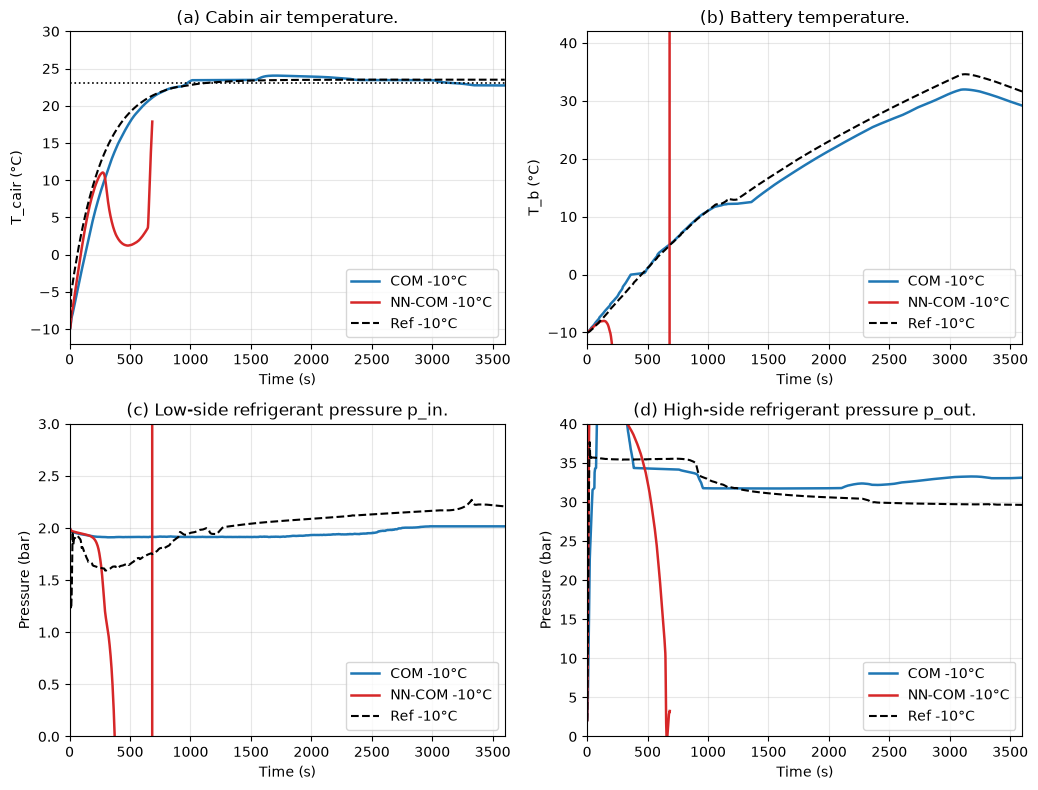

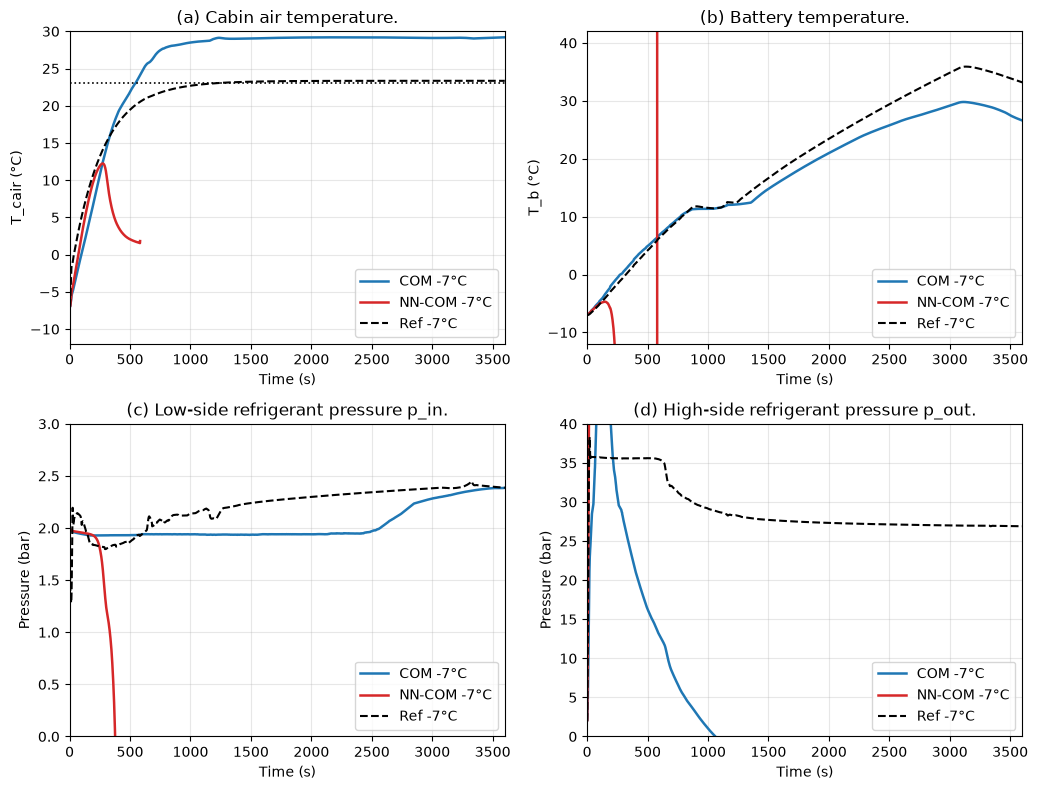

In [6]:
# Cell 6: Recreate Figure 2 of Lokur & Murgovski (2026) with NN-COM Added
import matplotlib.pyplot as plt

def plot_figure2_recreation(tamb=-10):
    res  = full_results[tamb]
    ref  = res["ref"]
    base = res["base"]
    nn_c = res["nn"]
    t = np.arange(ref.shape[0])

    fig, axes = plt.subplots(2, 2, figsize=(10.5, 8.0))

    # (a) Cabin air temperature
    ax = axes[0, 0]
    ax.plot(t, base[:, 8] - 273.15, "C0-",  lw=1.8, label=f"COM {tamb}°C")
    ax.plot(t, nn_c[:, 8] - 273.15, "C3-",  lw=1.8, label=f"NN-COM {tamb}°C")
    ax.plot(t, ref[:, 8]  - 273.15, "k--",  lw=1.5, label=f"Ref {tamb}°C")
    ax.axhline(23.0, color="k", ls=":", lw=1.2)
    ax.set_ylabel("T_cair (°C)")
    ax.set_xlabel("Time (s)")
    ax.set_title("(a) Cabin air temperature.")
    ax.set_xlim([0, 3600]); ax.set_ylim([-12, 30])
    ax.grid(True, alpha=0.3); ax.legend(loc="lower right", frameon=True)

    # (b) Battery temperature
    ax = axes[0, 1]
    ax.plot(t, base[:, 4] - 273.15, "C0-",  lw=1.8, label=f"COM {tamb}°C")
    ax.plot(t, nn_c[:, 4] - 273.15, "C3-",  lw=1.8, label=f"NN-COM {tamb}°C")
    ax.plot(t, ref[:, 4]  - 273.15, "k--",  lw=1.5, label=f"Ref {tamb}°C")
    ax.set_ylabel("T_b (°C)")
    ax.set_xlabel("Time (s)")
    ax.set_title("(b) Battery temperature.")
    ax.set_xlim([0, 3600]); ax.set_ylim([-12, 42])
    ax.grid(True, alpha=0.3); ax.legend(loc="lower right", frameon=True)

    # (c) Low-side refrigerant pressure p_in
    ax = axes[1, 0]
    ax.plot(t, base[:, 5] / 1e5, "C0-",  lw=1.8, label=f"COM {tamb}°C")
    ax.plot(t, nn_c[:, 5] / 1e5, "C3-",  lw=1.8, label=f"NN-COM {tamb}°C")
    ax.plot(t, ref[:, 5]  / 1e5, "k--",  lw=1.5, label=f"Ref {tamb}°C")
    ax.set_ylabel("Pressure (bar)")
    ax.set_xlabel("Time (s)")
    ax.set_title("(c) Low-side refrigerant pressure p_in.")
    ax.set_xlim([0, 3600]); ax.set_ylim([0, 3.0])
    ax.grid(True, alpha=0.3); ax.legend(loc="lower right", frameon=True)

    # (d) High-side refrigerant pressure p_out
    ax = axes[1, 1]
    ax.plot(t, base[:, 6] / 1e5, "C0-",  lw=1.8, label=f"COM {tamb}°C")
    ax.plot(t, nn_c[:, 6] / 1e5, "C3-",  lw=1.8, label=f"NN-COM {tamb}°C")
    ax.plot(t, ref[:, 6]  / 1e5, "k--",  lw=1.5, label=f"Ref {tamb}°C")
    ax.set_ylabel("Pressure (bar)")
    ax.set_xlabel("Time (s)")
    ax.set_title("(d) High-side refrigerant pressure p_out.")
    ax.set_xlim([0, 3600]); ax.set_ylim([0, 40.0])
    ax.grid(True, alpha=0.3); ax.legend(loc="lower right", frameon=True)

    plt.tight_layout()
    plt.show()

# Recreate Figure 2 (-10°C as in paper) and also view the unseen -7°C validation
plot_figure2_recreation(-10)
plot_figure2_recreation(-7)

In [8]:
# Diagnostic Cell: Inspect exact raw units of X, U, and baseline_TV before any conversion
import numpy as np

t10 = raw_data["T10"]
X_raw = np.asarray(t10.X, dtype=np.float64)
U_raw = np.asarray(t10.U, dtype=np.float64)
TV_raw = raw_data["baseline_TV"]

print("=== 1. Raw T10 States X (min / mean / max) ===")
for i, name in enumerate(["motT", "invT", "dcdcT", "SOC", "batT", "p_in", "p_out", "cabIntT", "cabAirT"]):
    print(f"  State {i+1} ({name:8s}): min={X_raw[:, i].min():10.3f} | mean={X_raw[:, i].mean():10.3f} | max={X_raw[:, i].max():10.3f}")

print("\n=== 2. Raw T10 Inputs U (min / mean / max) ===")
for i, name in enumerate(["compNrpm", "cabAirMfIn", "motPumpNrpm", "batPumpNrpm", "heaterCmd", "radFanrpm"]):
    print(f"  Input {i+1} ({name:11s}): min={U_raw[:, i].min():10.4f} | mean={U_raw[:, i].mean():10.4f} | max={U_raw[:, i].max():10.4f}")

print("\n=== 3. Raw baseline_TV.ambient unique values ===")
print("  ambient:", np.unique(TV_raw.ambient))

print("\n=== 4. Raw baseline_TV.states (min / mean / max) ===")
tv_s = np.asarray(TV_raw.states, dtype=np.float64)
for i in range(9):
    print(f"  TV.states[:, {i}]: min={tv_s[:, i].min():10.3f} | mean={tv_s[:, i].mean():10.3f} | max={tv_s[:, i].max():10.3f}")

print("\n=== 5. Raw baseline_TV.parameters (min / mean / max) ===")
tv_p = np.asarray(TV_raw.parameters, dtype=np.float64)
for i in range(11):
    print(f"  P({i+1:2d}): min={tv_p[:, i].min():10.4f} | mean={tv_p[:, i].mean():10.4f} | max={tv_p[:, i].max():10.4f}")

=== 1. Raw T10 States X (min / mean / max) ===
  State 1 (motT    ): min=   263.085 | mean=   297.168 | max=   321.607
  State 2 (invT    ): min=   263.150 | mean=   297.335 | max=   321.701
  State 3 (dcdcT   ): min=   263.150 | mean=   297.791 | max=   320.778
  State 4 (SOC     ): min=     0.868 | mean=     0.940 | max=     1.000
  State 5 (batT    ): min=   263.150 | mean=   296.294 | max=   320.268
  State 6 (p_in    ): min=191776.363 | mean=195613.072 | max=200000.000
  State 7 (p_out   ): min=200000.000 | mean=3241774.887 | max=3537120.016
  State 8 (cabIntT ): min=   263.150 | mean=   274.241 | max=   278.734
  State 9 (cabAirT ): min=   263.150 | mean=   287.332 | max=   294.363

=== 2. Raw T10 Inputs U (min / mean / max) ===
  Input 1 (compNrpm   ): min=    0.0000 | mean= 2035.0247 | max= 4466.9540
  Input 2 (cabAirMfIn ): min=    0.0000 | mean=    0.1078 | max=    0.1369
  Input 3 (motPumpNrpm): min=    0.0000 | mean=  898.6213 | max=  900.0000
  Input 4 (batPumpNrpm): min= 

In [9]:
# Diagnostic Cell: Inspect S.resampled (True Simscape Reference) vs S.States vs TV
import scipy.io as sio
import numpy as np

t10_full = sio.loadmat("../Data/tuning_data_10.mat", variable_names=["resampled", "States"],
                       squeeze_me=True, struct_as_record=False)
r10 = t10_full["resampled"]

# Build the 9 measured Simscape reference states from S.resampled
X_meas_10 = np.column_stack([
    r10.motTmeasC + 273.15,
    r10.invTmeasC + 273.15,
    r10.dcdcTmeasC + 273.15,
    r10.batSocMeas,
    r10.batTmeasC + 273.15,
    r10.compPinMpa * 1e6,
    r10.compPoutMpa * 1e6,
    r10.cabIntTInK if np.mean(r10.cabIntTInK) > 150 else r10.cabIntTInK + 273.15,
    r10.cabAirTmeasC + 273.15,
])

print("=== 1. True Simscape Reference (S.resampled.*meas*) at -10°C (in °C / bar) ===")
names_c = ["motT (°C)", "invT (°C)", "dcdcT (°C)", "SOC (-)", "batT (°C)", "p_in (bar)", "p_out (bar)", "cabIntT (°C)", "cabAirT (°C)"]
for i, nm in enumerate(names_c):
    col = X_meas_10[:, i].copy()
    if "(°C)" in nm: col -= 273.15
    elif "(bar)" in nm: col /= 1e5
    print(f"  {nm:13s}: min={col.min():8.3f} | mean={col.mean():8.3f} | max={col.max():8.3f}")

print("\n=== 2. Difference between S.States and S.resampled.*meas* at -10°C ===")
X_states_10 = t10_full["States"].T
for idx, nm in [(0, "T_mot"), (1, "T_inv"), (2, "T_dcdc"), (4, "T_b"), (8, "T_cair")]:
    diff = X_states_10[:len(X_meas_10), idx] - X_meas_10[:, idx]
    print(f"  {nm:8s}: RMSE = {np.sqrt(np.mean(diff**2)):6.2f}°C | MAE = {np.mean(np.abs(diff)):6.2f}°C")

print("\n=== 3. All 11 Baseline Parameters P(1)..P(11) in TV.parameters ===")
tv_p = np.asarray(raw_data["baseline_TV"].parameters, dtype=np.float64)
for i in range(11):
    print(f"  P({i+1:2d}): min={tv_p[:, i].min():8.4f} | mean={tv_p[:, i].mean():8.4f} | max={tv_p[:, i].max():8.4f}")

print("\n=== 4. Compare TV.states (rows 0..3600 and 3600..7200) vs X_meas_10 ===")
tv_s = np.asarray(raw_data["baseline_TV"].states, dtype=np.float64)
tv_a = np.asarray(raw_data["baseline_TV"].ambient, dtype=np.float64)
print("  TV.ambient first 5:", tv_a[:5], "| last 5:", tv_a[-5:])
mask_10 = (tv_a == -10)
print("  Max abs diff between TV.states[Tamb==-10] and X_meas_10:",
      np.max(np.abs(tv_s[mask_10, :5] - X_meas_10[:np.sum(mask_10), :5])))

=== 1. True Simscape Reference (S.resampled.*meas*) at -10°C (in °C / bar) ===
  motT (°C)    : min= -10.000 | mean=  18.922 | max=  34.861
  invT (°C)    : min= -10.000 | mean=  18.810 | max=  34.642
  dcdcT (°C)   : min= -10.000 | mean=  19.723 | max=  34.302
  SOC (-)      : min=   0.870 | mean=   0.941 | max=   1.000
  batT (°C)    : min= -10.000 | mean=  18.388 | max=  34.594
  p_in (bar)   : min=   1.235 | mean=   2.007 | max=   2.271
  p_out (bar)  : min=   2.000 | mean=  31.702 | max=  37.660
  cabIntT (°C) : min= -10.000 | mean=   1.517 | max=   5.584
  cabAirT (°C) : min= -10.000 | mean=  21.322 | max=  23.515

=== 2. Difference between S.States and S.resampled.*meas* at -10°C ===
  T_mot   : RMSE =   7.30°C | MAE =   5.97°C
  T_inv   : RMSE =   7.45°C | MAE =   6.08°C
  T_dcdc  : RMSE =   7.19°C | MAE =   6.07°C
  T_b     : RMSE =   6.65°C | MAE =   5.18°C
  T_cair  : RMSE =   8.83°C | MAE =   7.14°C

=== 3. All 11 Baseline Parameters P(1)..P(11) in TV.parameters ===
  P( 1)